# Финальная оценка CNN

По минимальному validation loss выбрана **SimpleCNN + Augmentation**: loss **0.4978**, accuracy **83.4%**, эпоха **10**. Загрузим её checkpoint `best_cnn_augmented.pth` и оценим на ранее не использованной test-выборке Intel Image Classification.

Модель уже выбрана. Тестовые результаты не используем для дополнительного подбора модели или обучения.

## 1. Подготовка

Запускаем локально в VS Code с ядром `.venv/bin/python`. Используем CUDA, если она доступна, иначе — CPU.


In [1]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", device)


Устройство: cpu


In [2]:
# Пути работают из корня проекта и из notebooks/.
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
checkpoint_path = project_root / "models" / "best_cnn_augmented.pth"
if not checkpoint_path.is_file():
    raise FileNotFoundError(f"Checkpoint не найден: {checkpoint_path}")


In [3]:
dataset_path = project_root / "data"
if not (dataset_path / "seg_test" / "seg_test").is_dir():
    # Используем kagglehub только при отсутствии локальной test-выборки.
    import kagglehub

    dataset_path = Path(kagglehub.dataset_download("puneet6060/intel-image-classification"))
print("Папка датасета:", dataset_path)


Папка датасета: /home/harun00000/ml/projects/image-classification/data


## 2. Тестовая выборка

Загрузим только `seg_test/seg_test`. Предобработка совпадает с validation победившей модели: `Resize((128, 128))` и `ToTensor()`, без случайных преобразований.


In [4]:
test_dir = Path(dataset_path) / "seg_test" / "seg_test"
test_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

test_dataset = datasets.ImageFolder(test_dir, transform=test_transform)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=0)
classes = test_dataset.classes

print("Изображений в test:", len(test_dataset))
print("Классы:", ", ".join(classes))


Изображений в test: 3000
Классы: buildings, forest, glacier, mountain, sea, street


## 3. Загрузка модели

Для SimpleCNN + Augmentation используем класс `SimpleCNN` из второго ноутбука и загрузим сохранённые веса. Проверим порядок классов: числовые метки должны означать одно и то же в checkpoint и test.


In [5]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), 
            nn.ReLU(),
            nn.MaxPool2d(2),                            
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.flatten = nn.Flatten()                     
        self.classifier = nn.Sequential(
            nn.Linear(64 * 16 * 16, 128),              
            nn.ReLU(),
            nn.Linear(128, 6),
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.flatten(x)
        return self.classifier(x)

checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
if list(checkpoint["classes"]) != classes:
    raise ValueError("Порядок классов в checkpoint и тестовом датасете не совпадает.")

model = SimpleCNN().to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
print("Загружен checkpoint:", checkpoint_path.name)


Загружен checkpoint: best_cnn_augmented.pth


## 4. Финальная оценка

Пройдём по всем тестовым изображениям без вычисления градиентов. В отчёте macro average даёт одинаковый вес каждому классу, weighted average учитывает число изображений в классе.


In [6]:
criterion = nn.CrossEntropyLoss(reduction="sum")
total_loss = 0.0
y_true, y_pred = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        logits = model(images)

        # Сумма потерь корректно учитывает последний неполный батч.
        total_loss += criterion(logits, labels).item()
        y_true.extend(labels.cpu().tolist())
        y_pred.extend(logits.argmax(dim=1).cpu().tolist())

test_loss = total_loss / len(y_true)
test_accuracy = sum(true == pred for true, pred in zip(y_true, y_pred)) / len(y_true)
class_ids = list(range(len(classes)))

report = classification_report(
    y_true, y_pred, labels=class_ids, target_names=classes,
    output_dict=True, zero_division=0,
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.1%} ({len(y_true)} изображений)")
print()
print(classification_report(
    y_true, y_pred, labels=class_ids, target_names=classes,
    digits=3, zero_division=0,
))


Test loss: 0.4921
Test accuracy: 82.7% (3000 изображений)

              precision    recall  f1-score   support

   buildings      0.752     0.881     0.811       437
      forest      0.982     0.916     0.948       474
     glacier      0.785     0.758     0.771       553
    mountain      0.771     0.796     0.784       525
         sea      0.824     0.825     0.825       510
      street      0.878     0.804     0.840       501

    accuracy                          0.827      3000
   macro avg      0.832     0.830     0.830      3000
weighted avg      0.831     0.827     0.828      3000



## 5. Матрица ошибок

Строки — истинные классы, столбцы — предсказанные. На диагонали находятся правильные ответы; остальные ячейки показывают, какие классы модель путает. Здесь указано количество изображений.


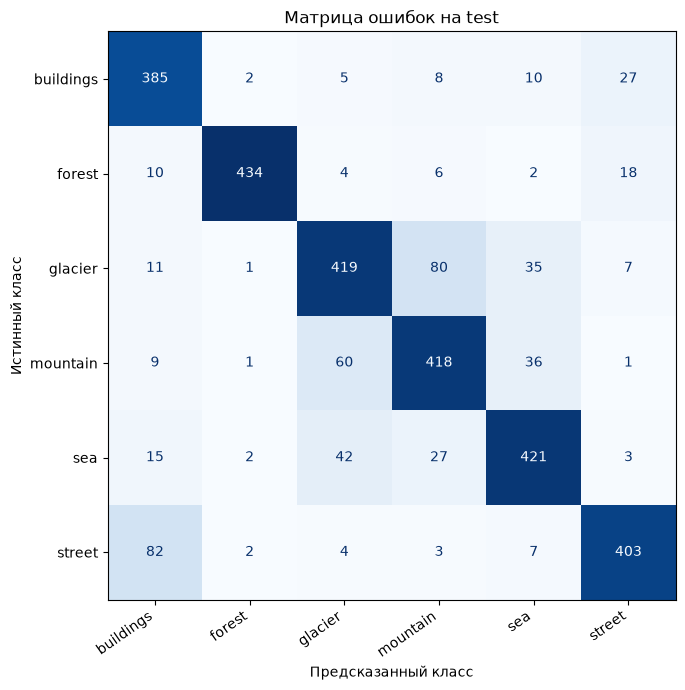

In [7]:
cm = confusion_matrix(y_true, y_pred, labels=class_ids)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False,
)

ax.set_title("Матрица ошибок на test")
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Истинный класс")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
fig.tight_layout()
plt.show()


## 6. Примеры предсказаний

Посмотрим на фиксированную случайную выборку из test и отдельно на ошибки. Поскольку DataLoader не перемешивает данные, позиции предсказаний совпадают с индексами ImageFolder.


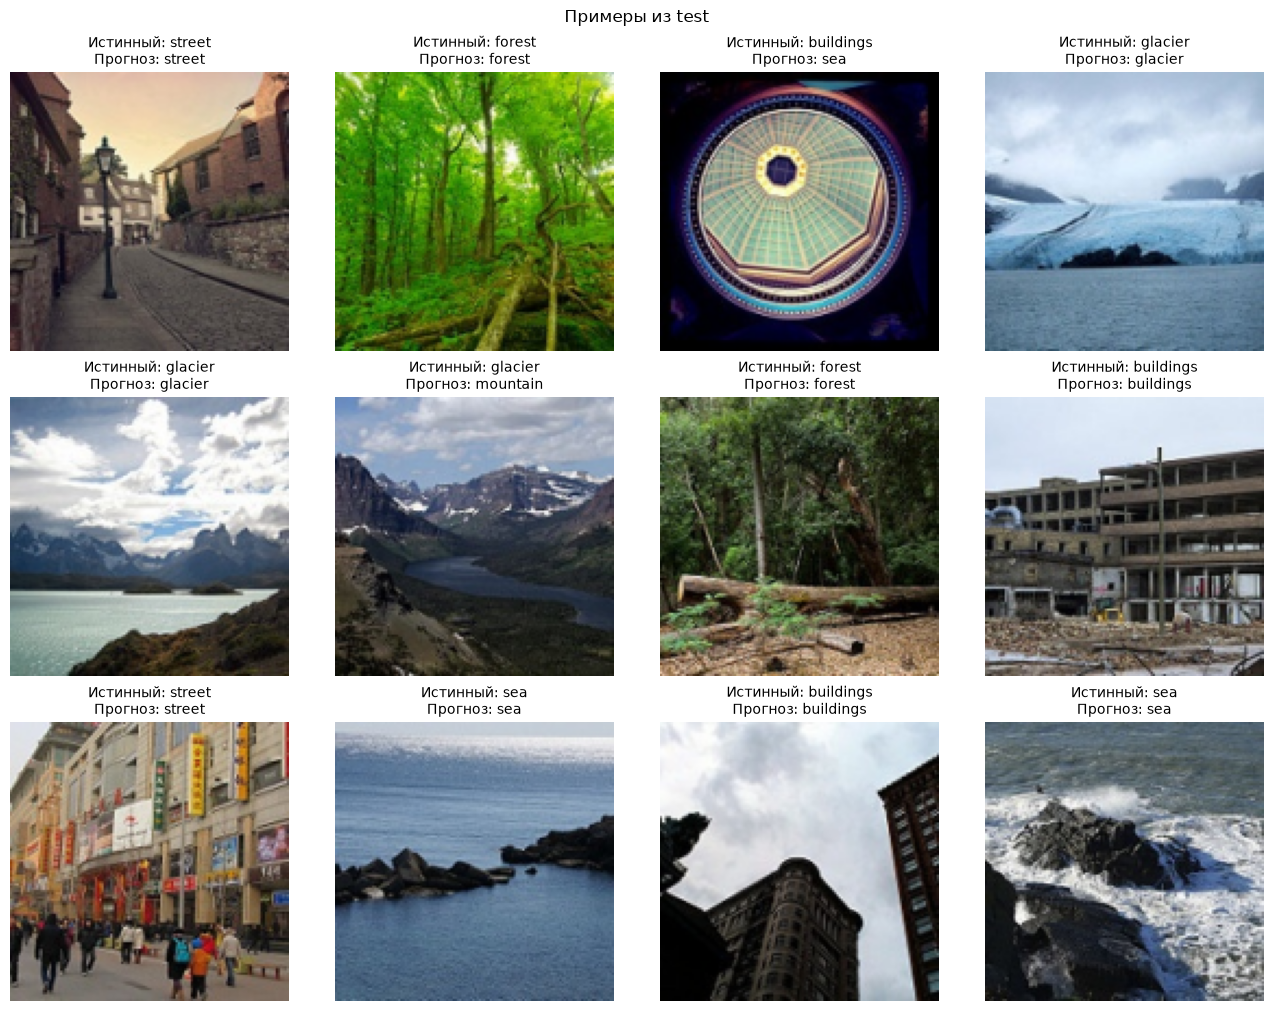

In [8]:
example_indices = random.Random(SEED).sample(range(len(test_dataset)), min(12, len(test_dataset)))
fig, axes = plt.subplots(3, 4, figsize=(13, 10), layout="constrained")
for ax in axes.flat:
    ax.axis("off")
for ax, index in zip(axes.flat, example_indices):
    image, label = test_dataset[index]
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(
        f"Истинный: {classes[label]}\nПрогноз: {classes[y_pred[index]]}",
        fontsize=10,
    )
fig.suptitle("Примеры из test")
plt.show()


Ошибок: 520 из 3000


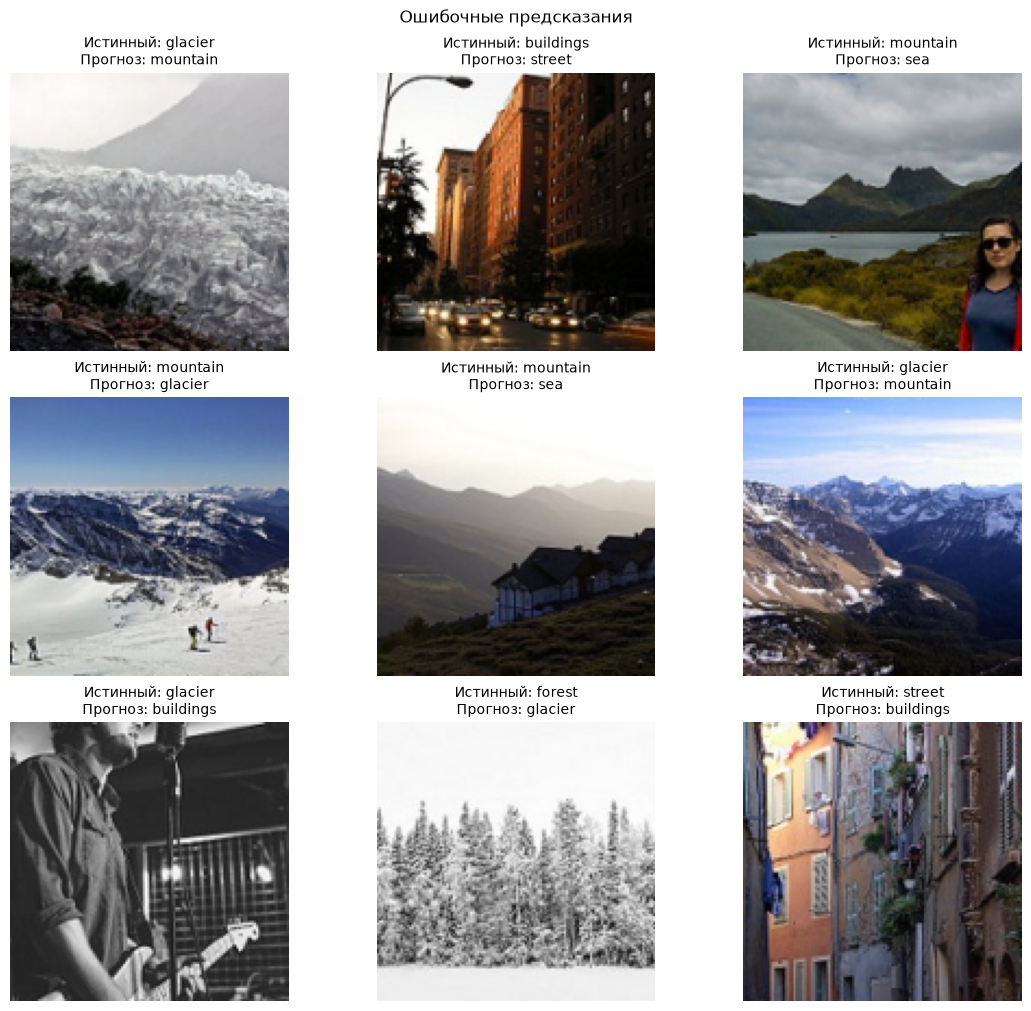

In [9]:
error_indices = [i for i, (true, pred) in enumerate(zip(y_true, y_pred)) if true != pred]
print(f"Ошибок: {len(error_indices)} из {len(y_true)}")
if error_indices:
    shown_errors = random.Random(SEED).sample(error_indices, min(9, len(error_indices)))
    fig, axes = plt.subplots(3, 3, figsize=(11, 10), layout="constrained")
    for ax in axes.flat:
        ax.axis("off")
    for ax, index in zip(axes.flat, shown_errors):
        image, label = test_dataset[index]
        ax.imshow(image.permute(1, 2, 0))
        ax.set_title(
            f"Истинный: {classes[label]}\nПрогноз: {classes[y_pred[index]]}",
            fontsize=10,
        )
    fig.suptitle("Ошибочные предсказания")
    plt.show()
else:
    print("Ошибочных предсказаний нет.")


## 7. Выводы

Итоги ниже вычисляются после оценки: качество на test, классы с наибольшим и наименьшим F1 и самые частые направленные ошибки. Сопоставим test accuracy с **83.4%** на validation; разница описывает эти две выборки и не служит основанием для новой настройки модели.


In [10]:
validation_accuracy = 0.834
print(f"Test accuracy: {test_accuracy:.1%}; test loss: {test_loss:.4f}")
print(f"Validation accuracy выбранной модели: {validation_accuracy:.1%}")
print(f"Разница test − validation: {100 * (test_accuracy - validation_accuracy):+.1f} п.п.")

best_f1 = max(report[name]["f1-score"] for name in classes)
worst_f1 = min(report[name]["f1-score"] for name in classes)
best_classes = [name for name in classes if report[name]["f1-score"] == best_f1]
worst_classes = [name for name in classes if report[name]["f1-score"] == worst_f1]
print(f"Наибольший F1: {', '.join(best_classes)} ({best_f1:.3f})")
print(f"Наименьший F1: {', '.join(worst_classes)} ({worst_f1:.3f})")

confusions = [
    (int(cm[i, j]), classes[i], classes[j])
    for i in class_ids for j in class_ids if i != j and cm[i, j] > 0
]
confusions.sort(key=lambda item: item[0], reverse=True)
if confusions:
    print("Самые частые ошибки (истинный → предсказанный):")
    for count, true_class, predicted_class in confusions[:3]:
        print(f"  {true_class} → {predicted_class}: {count}")
else:
    print("Ошибок на test нет.")


Test accuracy: 82.7%; test loss: 0.4921
Validation accuracy выбранной модели: 83.4%
Разница test − validation: -0.7 п.п.
Наибольший F1: forest (0.948)
Наименьший F1: glacier (0.771)
Самые частые ошибки (истинный → предсказанный):
  street → buildings: 82
  glacier → mountain: 80
  mountain → glacier: 60


## 8. Доверительный интервал для accuracy

Рассчитаем 95% доверительный интервал методом Уилсона по уже полученным предсказаниям. Он показывает неопределённость оценки accuracy на конечной тестовой выборке.

При повторении такой процедуры примерно 95% интервалов будут содержать истинную вероятность правильного ответа. Предполагаем, что тестовые изображения независимы и представляют данные, на которых будет применяться модель.


In [11]:
from scipy.stats import binomtest

n_test = len(y_true)
n_correct = sum(true == pred for true, pred in zip(y_true, y_pred))
accuracy_estimate = n_correct / n_test

# Двусторонний интервал для доли правильных ответов.
accuracy_summary = binomtest(k=n_correct, n=n_test, alternative="two-sided")
wilson_ci = accuracy_summary.proportion_ci(confidence_level=0.95, method="wilson")

print(f"Test accuracy: {accuracy_estimate:.2%}")
print(f"95% доверительный интервал (Уилсон): [{wilson_ci.low:.2%}; {wilson_ci.high:.2%}]")


Test accuracy: 82.67%
95% доверительный интервал (Уилсон): [81.27%; 83.98%]


## 9. Проверка статистической гипотезы

Проверим долю правильных ответов односторонним точным биномиальным тестом:

- **H0:** вероятность правильной классификации равна 1/6.
- **H1:** вероятность правильной классификации больше 1/6.

Уровень значимости **α = 0.05**. Вероятность 1/6 соответствует случайному равновероятному выбору одного из шести классов. Это достаточно слабый ориентир: тест не показывает превосходство над другими обученными CNN.

Если вычисленное p-value округлится до нуля, это означает ограничение численной точности, а не точное нулевое значение.


In [12]:
alpha = 0.05
binomial_result = binomtest(k=n_correct, n=n_test, p=1 / 6, alternative="greater")

print(f"Правильных ответов: {n_correct} из {n_test}")
print(f"p-value: {binomial_result.pvalue:.3e}")
if binomial_result.pvalue == 0:
    print("p-value округлилось до нуля из-за ограниченной численной точности.")

if binomial_result.pvalue < alpha:
    print("Отвергаем H0 при α = 0.05.")
    print("Есть статистические основания считать вероятность правильного ответа выше 1/6.")
else:
    print("Не отвергаем H0 при α = 0.05.")
    print("Недостаточно оснований считать вероятность правильного ответа выше 1/6.")


Правильных ответов: 2480 из 3000
p-value: 0.000e+00
p-value округлилось до нуля из-за ограниченной численной точности.
Отвергаем H0 при α = 0.05.
Есть статистические основания считать вероятность правильного ответа выше 1/6.


# ИТОГИ

1) Итоговой моделью выбрана **SimpleCNN + Augmentation**: она показала наименьший validation loss среди рассмотренных вариантов.
2) На отложенной тестовой выборке из 3000 изображений модель получила accuracy 82.7% и loss 0.4921. Test accuracy близка к validation accuracy (83.4%); разница составляет 0.7 процентного пункта.
3) Лучше всего модель распознаёт forest (F1 = 0.948). Основные ошибки связаны с путаницей между glacier и mountain, а также между street и buildings.
4) По 2480 правильным ответам из 3000 получен 95% доверительный интервал Уилсона **[81.27%; 83.98%]**. Он отражает неопределённость оценки accuracy на конечной выборке при предположении независимости изображений.
5) Односторонний биномиальный тест отвергает H0 при α = 0.05: вероятность правильного ответа выше 1/6. Вычисленное p-value округлилось до нуля из-за численной точности, а не равно нулю в точности. Случайный равновероятный выбор - слабый ориентир; этот результат не доказывает превосходство над другими обученными CNN. Модель выбрана по validation, без дополнительной настройки на test.
